# Retail Sales Explorer - step-by-step project notebook

**Business Analytics Workshop | CookieSensei Labs | Python 3.12**

Work through **what we are doing, why it is useful, how the code works, and what its output means**. The explanations are Markdown cells, and the analysis is in editable Python code cells with saved results. All records are fictional teaching data; monetary values are INR.

Keep this notebook with [retail_sales.csv](retail_sales.csv) and [app.py](app.py). The [Markdown companion](EXPLANATION.md) provides a continuous reading version. The source application and data used here match revision `c10a61c36fffdd048b69dd78926e6663bc986fce`.

## Your notebook learning route

Connect each business question to its rows, arithmetic and chart. Your objectives:

- Trace an order from its source fields to discounted sales and gross profit.
- Explain how changing a selection changes every result that depends on it.
- Choose between a total, a weighted margin and an order-level distribution.
- Describe how the same analysis becomes an interactive decision aid in [app.py](app.py).

### Know what a row represents

One source row records one order, with region, category and channel. Several units can belong to one order. The source also does not provide a customer identifier: counting orders cannot establish how many different customers bought something. Keep this sentence beside your work: **“My population is the selected orders; my measures have stated units.”** It prevents a mathematically correct calculation from answering the wrong business question.

### Give each tool a clear job

| Tool | Its job in this lesson | What you should inspect |
| --- | --- | --- |
| Python and `Path` | Locate the CSV, name intermediate results and express the calculation sequence | The working directory and variable names |
| pandas | Load, type, filter, derive, group and export tables | Row counts, column types and aggregation rules |
| Plotly Express | Draw the monthly trend and regional category mix | The grouped table behind each chart |
| Matplotlib and Seaborn | Draw the histogram, boxplot and correlation heatmap | Whether the input is orders or summaries |
| Streamlit | Turn choices into controls and results into browser components | Which calculations must rerun after a choice |

Why pandas here? These questions repeatedly operate on named columns and groups of rows. A DataFrame keeps those relationships visible; a selected column is usually a Series. Column arithmetic calculates the same rule for every retained order, while `groupby` changes the level of detail. Pandas performs those operations; you still decide whether a sum, mean or ratio has the correct business meaning.

### Work with the kernel deliberately

The notebook kernel remembers variables between executions. `frame` holds the typed source data; `filtered` holds the current selection; `category_summary` holds grouped results; `revenue` is a single total. Read those names as a sequence of changing levels of detail: **orders → selected orders → measures → summaries → evidence**.

Run the analysis cells in their numbered order. When you change the selection cell, rerun the dependent cells after it; an old chart does not update merely because an earlier variable changed. Restart the kernel and rerun the analysis to expose forgotten interactive state.

## How to work through this notebook

1. Open `TUTORIAL.ipynb` in JupyterLab or VS Code and select the workshop's Python 3.12 environment.
2. Read the question above a code cell, predict the result, then use **Shift+Enter** to run that cell.
3. Run cells from top to bottom. Python variables stay in the kernel's memory; changing an earlier cell requires rerunning the cells that depend on it.
4. Compare the output with the interpretation underneath. Try the checkpoints before moving on.
5. Use **Restart Kernel and Run All Cells** to reproduce the baseline from a clean session. All executable cells here finish without launching a long-running web server.

The first code cell locates this project and configures notebook chart display. It supports starting in the project folder, the workshop folder, or the repository root. It changes only the kernel's working directory; it does not move any files.

The complete Streamlit teaching script later in this notebook is a **reference code block in a Markdown cell**. Copy it into the stated separate `.py` file to launch its browser interface. The runnable `AppTest` section independently inspects the existing `app.py` and demonstrates a filter rerun inside the notebook. These two execution contexts are explained separately.

Saved figure outputs include embedded PNG previews. In a running JupyterLab or VS Code notebook, Plotly can also display interactive figures. A GitHub preview shows the saved notebook and cannot execute Python. Keep the CSV and app beside the notebook when downloading it for execution. Local JupyterLab users can install the notebook interface with `python -m pip install jupyterlab`; the prepared Cloud Lab already supplies it. Analysis package versions are listed in the [workshop setup](../README.md).

In [1]:
from pathlib import Path                  # Represent a folder or filename as a Python object.
import os                                # Change this kernel's working directory when necessary.
import sys                               # Inspect the Python version selected by the kernel.
from IPython.display import display      # Render tables and figures as notebook outputs.
import matplotlib
import plotly.io as pio

# Support opening the notebook from this folder, the workshop, or the repo root.
notebook_start = Path.cwd()
candidate_folders = [
    notebook_start,
    notebook_start / '01_retail_sales',
    notebook_start / 'business_analytics_workshop' / '01_retail_sales',
]
PROJECT_DIR = next(
    (folder for folder in candidate_folders
     if (folder / 'retail_sales.csv').is_file() and (folder / 'app.py').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook with its sibling CSV and app.py in the project folder.')
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)

# Inline figures belong below their code cells; the Plotly renderer is used by JupyterLab/VS Code.
matplotlib.use('module://matplotlib_inline.backend_inline')
pio.renderers.default = 'plotly_mimetype'
print('Project folder:', PROJECT_DIR.name)
print('CSV and app.py found.')
print('Python:', sys.version.split()[0])

Project folder: 01_retail_sales
CSV and app.py found.
Python: 3.12.14


### Python vocabulary you will use repeatedly

| Code pattern | What it means | Why it appears here |
| --- | --- | --- |
| `name = expression` | Calculate a value and give it a name | Later cells can reuse the result |
| `import pandas as pd` | Import a library with a short alias | `pd.read_csv(...)` calls its CSV reader |
| `frame["column"]` | Select one named column as a Series | Apply a calculation to that measure |
| `frame[mask]` | Keep rows whose Boolean condition is `True` | Define the population being analyzed |
| `.method(...)` | Ask an object to perform an operation | `.sum()`, `.mean()` and `.groupby()` answer different questions |
| `# explanation` | A comment Python does not execute | Describe the purpose of the next operation |
| `f"...{value:.2f}..."` | Put a formatted value into a string | Communicate results without changing the underlying value |

Indentation groups statements inside a `for`, `if`, function or `with` block. Brackets, parentheses and column spelling matter. When a cell fails, read the final error message, inspect the named variable or column, and fix the earliest failed step before continuing.

## The business problem

A retail manager has order records but needs answers: How much did we sell after discounts? How much remained after paying product costs? Which regions and categories contributed most? Is the average order representative? Are monthly sales and profit moving together?

One total cannot answer all these questions. High revenue can come from many orders, expensive products, or deep discounts. A category can lead sales while earning little margin. A large order can move the mean far above a typical order. The solution is to keep the original observations inspectable, calculate explicit measures, compare groups, and show distributions as well as totals.

This is exploratory data analysis (EDA). It helps choose a pricing, cost or merchandising question to investigate. It does not establish that a discount causes higher demand, calculate net profit, or forecast sales. Those tasks would require additional data and methods.

## Environment and first principles

Use Python 3.12 and the versions documented in the [workshop README](../README.md):

```bash
python -m pip install streamlit==1.50.0 pandas==2.2.3 numpy==2.3.5 matplotlib==3.10.8 seaborn==0.13.2 plotly==6.5.2
```

Use your workshop environment or a virtual environment. The repository's root README recommends a Linux Cloud Lab or WSL for a full clone because other phase folders contain `>` characters that native Windows filenames cannot represent. The project itself needs the CSV and installed packages, not an API key or database.

**Why pandas?** The input is a table, and the questions require table operations: parsing, selecting rows, calculating columns, grouping, aggregation and export. A pandas **DataFrame** stores a two-dimensional labeled table. Selecting one column usually returns a **Series**. The library lets the business operation remain visible instead of requiring a manual loop and dictionary for every total. Pandas performs arithmetic; it does not decide which denominator or business interpretation is correct.

**Why the other tools?** `Path` handles filenames. Matplotlib provides figure/axes control and the histogram. Seaborn builds the boxplot and heatmap on Matplotlib axes. Plotly Express builds interactive line and bar figures. Streamlit supplies the browser interface, widgets and downloads. NumPy belongs to the workshop environment but is not directly imported by this app.

In the analysis cells, `display(fig)` renders the figure below the code. Matplotlib cells then call `plt.close(fig)` to release the figure handle while preserving the displayed output. The output below each chart cell is produced by executing that cell. Plotly's saved PNG is a static view; the live Plotly figure in a notebook or Streamlit additionally supports hover and zoom.

## Part 1 - Load and understand the orders

### Step 01 - Load the CSV as a pandas table

**Question:** What data do we actually have to analyze?

In [2]:
from pathlib import Path  # Build a path without hard-coding a machine-specific folder.
import pandas as pd       # Read and transform tables.
import matplotlib.pyplot as plt  # Create figures and axes.
import plotly.express as px      # Build interactive charts from DataFrames.
import seaborn as sns            # Create statistical distribution plots.

# In a notebook, start in the folder containing retail_sales.csv.
DATA_FILE = Path("retail_sales.csv")
frame = pd.read_csv(DATA_FILE)  # CSV headers become DataFrame column names.

# shape gives (rows, columns); it does not count units or customers.
print(f"Loaded {frame.shape[0]} rows and {frame.shape[1]} source columns.")
print("Source file:", DATA_FILE.name)

Loaded 720 rows and 9 source columns.
Source file: retail_sales.csv


**Interpretation and reasoning**

`pd` is just an alias for pandas. `read_csv()` parses text into a DataFrame called `frame`. Here one row is one order, so 720 rows mean 720 recorded orders. A quantity column can contain several units per order. In the existing script, `Path(__file__).resolve().with_name(...)` finds the CSV beside `app.py`; notebooks usually have no `__file__`, so this cell deliberately uses the notebook's project working directory.

### Step 02 - Look at actual orders before calculating anything

**Question:** What does one record mean, and which quantities belong together?

In [3]:
# head(5) selects the first five rows without changing frame.
# to_string produces a stable text table; index=False hides the pandas row index.
print(frame.head(5).to_string(index=False))

order_id order_date region category channel  units  unit_price  discount_pct  unit_cost
ORD-0001 2025-01-01   West     Home   Store      7     1043.19           0.0     658.69
ORD-0002 2025-01-02   East     Home  Online      2      766.05           0.0     435.11
ORD-0003 2025-01-03  South     Home   Store      7     1098.99           0.0     807.30
ORD-0004 2025-01-04   West     Home  Online      8      860.70          10.0     574.83
ORD-0005 2025-01-05   West     Home   Store      3     1143.13          10.0     837.20


### Notebook skill - inspect a table directly

The printed preview above is useful in scripts and text reports. A notebook can also render the DataFrame itself as a table. `head(5)` returns a small view for inspection; it does not replace the full source table. Compare the row labels on the left with any business identifier column.

In [4]:
# Display the same source as a notebook table; keep frame unchanged.
display(frame.head(5))

,order_id,order_date,region,category,channel,units,unit_price,discount_pct,unit_cost
0,ORD-0001,2025-01-01,West,Home,Store,7,1043.19,0.0,658.69
1,ORD-0002,2025-01-02,East,Home,Online,2,766.05,0.0,435.11
2,ORD-0003,2025-01-03,South,Home,Store,7,1098.99,0.0,807.30
3,ORD-0004,2025-01-04,West,Home,Online,8,860.70,10.0,574.83
4,ORD-0005,2025-01-05,West,Home,Store,3,1143.13,10.0,837.20


**Interpretation and reasoning**

An order has one region, one category and one channel in this simplified dataset. `unit_price` and `unit_cost` are INR per unit; `units` is the quantity; `discount_pct` is percentage points, so 10 means 10%. `order_id` is a business identifier, distinct from pandas' row index. There are no customer IDs, refunds or operating expenses in these rows. Revenue and gross profit are not source columns: we will derive them.

### Step 03 - Convert text dates and numeric measures to usable types

**Question:** Why cannot we treat all CSV values as ordinary text?

In [5]:
print("Date type before conversion:", frame["order_date"].dtype)

# Dates must be parsed before chronological filtering and monthly grouping.
frame["order_date"] = pd.to_datetime(frame["order_date"], errors="raise")

# These columns must support arithmetic, not string concatenation.
numeric_columns = ["units", "unit_price", "discount_pct", "unit_cost"]
for column in numeric_columns:
    frame[column] = pd.to_numeric(frame[column], errors="raise")

print("\nTypes after conversion:")
print(frame.dtypes.to_string())

Date type before conversion: object

Types after conversion:
order_id                object
order_date      datetime64[ns]
region                  object
category                object
channel                 object
units                    int64
unit_price             float64
discount_pct           float64
unit_cost              float64


**Interpretation and reasoning**

A date stored as text does not supply pandas' datetime operations. A number stored as a string can fail arithmetic or behave differently from a number. `errors='raise'` makes invalid data visible rather than silently replacing it. `frame['units']` selects one Series; assigning a converted Series back updates that column. This conversion does not prove a number is sensible: negative quantities or discounts above 100 still need domain validation.

### Step 04 - Check the schema, missing values and duplicate rows

**Question:** Are the essential inputs present and usable?

In [6]:
required_columns = [
    "order_id", "order_date", "region", "category", "channel",
    "units", "unit_price", "discount_pct", "unit_cost",
]

# issubset allows extra columns but requires every named analysis input.
if not set(required_columns).issubset(frame.columns):
    raise ValueError("The CSV is missing required columns.")
if frame.empty:
    raise ValueError("The CSV contains no rows.")

# First any() reduces each column; second any() reduces to one yes/no result.
if frame[required_columns].isna().any().any():
    raise ValueError("Fill missing required values before analysis.")

quality = pd.DataFrame({
    "column": frame.columns,
    "type": frame.dtypes.astype(str).values,
    "missing": frame.isna().sum().values,
})
print(quality.to_string(index=False))
print("Exact duplicate rows:", int(frame.duplicated().sum()))
print("Distinct order IDs:", frame["order_id"].nunique())

      column           type  missing
    order_id         object        0
  order_date datetime64[ns]        0
      region         object        0
    category         object        0
     channel         object        0
       units          int64        0
  unit_price        float64        0
discount_pct        float64        0
   unit_cost        float64        0
Exact duplicate rows: 0
Distinct order IDs: 720


**Interpretation and reasoning**

The bundled file passes these checks. Missing required values should be corrected deliberately; the app does not automatically drop rows or fill them with zero. `duplicated()` compares entire rows and counts later copies; a repeated ID with changed amounts is a different issue. The distinct-ID check is an additional teaching inspection, not a uniqueness validation implemented by the app. The existing app wraps loading/conversion in `try/except` and uses `st.error()` plus `st.stop()`; a notebook normally shows the raised error directly.

### Step 05 - Inspect the available dates and business groups

**Question:** Which comparisons and filters are possible?

In [7]:
# min/max describe observed data coverage, not an audited trading calendar.
print("Observed dates:", frame["order_date"].min().date(),
      "to", frame["order_date"].max().date())

# unique() removes repeated labels; sorted() produces a predictable order.
for column in ["region", "category", "channel"]:
    print(f"{column}: {', '.join(sorted(frame[column].unique()))}")

# size counts order rows, not units sold.
print("\nOrders per region:")
print(frame.groupby("region").size().rename("orders").to_string())

Observed dates: 2025-01-01 to 2025-06-29
region: East, North, South, West
category: Electronics, Fashion, Grocery, Home
channel: Online, Store

Orders per region:
region
East     168
North    191
South    166
West     195


**Interpretation and reasoning**

The observed period ends on 29 June, even though the static case description says January-June. A missing date is not automatically a zero-sales day. Group sizes matter because a larger regional total may reflect more orders. `channel` exists in the data, but the current source app's sidebar filters region, category and dates only; adding a channel control is an extension.

## Part 2 - Filter and calculate business measures

### Checkpoint - Predict the population

Before filtering, predict whether the default selection should retain every row. Then inspect its count. If you select one category, which later totals must be recalculated? Explain why a different displayed count is a change of scope, not automatically a data-quality failure.

### Step 06 - Apply the same default selection as the app

**Question:** How do user choices become a precise analysis population?

In [8]:
# These variables represent the default values returned by sidebar widgets.
selected_regions = sorted(frame["region"].unique())
selected_categories = sorted(frame["category"].unique())
dates = (frame["order_date"].min().date(), frame["order_date"].max().date())

filtered = frame.copy()  # Keep the full source available for quality reporting.
filtered = filtered[filtered["region"].isin(selected_regions)]
filtered = filtered[filtered["category"].isin(selected_categories)]
filtered = filtered[filtered["order_date"].dt.date.between(dates[0], dates[1])]

if filtered.empty:
    raise ValueError("No rows match the selected groups and dates.")
print(f"Selected {len(filtered)} of {len(frame)} orders.")
print(f"Requested interval: {dates[0]} to {dates[1]} (inclusive)")

# A second mask demonstrates a narrower selection without changing filtered.
north_mask = frame["region"].isin(["North"])
print("Rows a North-only selection would keep:", int(north_mask.sum()))

Selected 720 of 720 orders.
Requested interval: 2025-01-01 to 2025-06-29 (inclusive)
Rows a North-only selection would keep: 191


**Interpretation and reasoning**

`.isin(...)` creates one True/False value per row. Outer indexing retains True rows. Sequential region, category and date filters combine as AND: every surviving order satisfies all three. `.between()` is inclusive by default. The main tutorial keeps all default rows so its results can be compared directly with the app. The separate North mask shows a real narrower selection without silently changing subsequent cells. In a live widget, selecting no labels keeps no rows; it does not mean 'all'.

### Step 07 - Derive net sales and gross profit for each order

**Question:** What did each order sell for after discounts, and what remained after product cost?

In [9]:
# Turn percentage points into a fraction, then keep the undiscounted fraction.
filtered["revenue"] = (
    filtered["units"] * filtered["unit_price"]
    * (1 - filtered["discount_pct"] / 100)
)

# Both revenue and cost cover all units in the same order.
filtered["gross_profit"] = (
    filtered["revenue"] - filtered["units"] * filtered["unit_cost"]
)
preview_columns = [
    "order_id", "units", "unit_price", "discount_pct",
    "unit_cost", "revenue", "gross_profit",
]
print(filtered[preview_columns].head(5).to_string(index=False))

# Check one actual order manually against the vectorized calculation.
first = filtered.iloc[0]  # iloc[0] selects the first row by position.
print(f"\n{first['order_id']}: {first['units']} units x INR {first['unit_price']:.2f}")
print(f"Net sales: INR {first['revenue']:.2f}; gross profit: INR {first['gross_profit']:.2f}")

order_id  units  unit_price  discount_pct  unit_cost  revenue  gross_profit
ORD-0001      7     1043.19           0.0     658.69 7302.330      2691.500
ORD-0002      2      766.05           0.0     435.11 1532.100       661.880
ORD-0003      7     1098.99           0.0     807.30 7692.930      2041.830
ORD-0004      8      860.70          10.0     574.83 6197.040      1598.400
ORD-0005      3     1143.13          10.0     837.20 3086.451       574.851

ORD-0001: 7 units x INR 1043.19
Net sales: INR 7302.33; gross profit: INR 2691.50


**Interpretation and reasoning**

Pandas multiplies aligned Series row by row, so the formula is applied to every selected order without a manual loop. Parentheses ensure the retained fraction is calculated before multiplication. The first source order has 7 units, no discount and INR 658.69 cost per unit: sales are INR 7,302.33 and gross profit is INR 2,691.50. `revenue` here means sales after the stated discount; it is not verified cash collected. Gross profit excludes operating expenses and tax. `frame` still has nine source columns; `filtered` now has eleven.

### Step 08 - Calculate the KPIs and a typical-order comparison

**Question:** What does the selected business look like overall?

In [10]:
def ratio(numerator, denominator):
    # This matches the source helper's scalar zero-denominator fallback.
    return numerator / denominator if denominator else 0.0

revenue = filtered["revenue"].sum()          # Add selected order sales.
profit = filtered["gross_profit"].sum()     # Add selected order profits.
average_order = filtered["revenue"].mean()  # One row is one order.
median_order = filtered["revenue"].median() # Middle ordered value.

print(f"Net sales: INR {revenue:,.2f}")
print(f"Gross profit: INR {profit:,.2f}")
print(f"Gross margin: {ratio(profit, revenue):.2%}")
print(f"Average order: INR {average_order:,.2f}")
print(f"Median order: INR {median_order:,.2f}")

Net sales: INR 3,014,163.59
Gross profit: INR 991,908.14
Gross margin: 32.91%
Average order: INR 4,186.34
Median order: INR 2,847.03


**Interpretation and reasoning**

A total adds amounts. A mean divides by the number of orders. Margin divides total gross profit by total sales, answering how much of each sales rupee remains after product cost. It is margin, not markup on cost. The mean exceeds the median, motivating the distribution chart below. `:,.2f` inserts separators and two decimal places; `:.2%` formats a fraction as a percentage. Formatting does not change the stored numbers. The source app's cards round some INR amounts to whole rupees; its report is more precise. The net-sales intermediate is approximately 3,014,163.595; floating-point representation causes the shown two-decimal formatting to end in .59. The app does not apply an accounting-grade per-order currency rounding policy.

### Step 09 - Demonstrate why total margin is not the mean of order margins

**Question:** Why does the app divide totals instead of averaging percentages?

In [11]:
# Zero revenue makes an individual margin undefined, represented here by NaN.
order_margins = filtered["gross_profit"].div(
    filtered["revenue"].replace(0, float("nan"))
)
simple_mean = order_margins.mean()

# Each order's weight is its revenue share, not an equal 1/order-count share.
revenue_weights = filtered["revenue"] / revenue
weighted_margin = (order_margins * revenue_weights).sum()

print(f"Unweighted mean of order margins: {simple_mean:.2%}")
print(f"Revenue-weighted order margin:    {weighted_margin:.2%}")
print(f"Total profit / total revenue:    {ratio(profit, revenue):.2%}")

Unweighted mean of order margins: 32.24%
Revenue-weighted order margin:    32.91%
Total profit / total revenue:    32.91%


**Interpretation and reasoning**

A small order and a large order should not receive equal influence when the question is profit per rupee of total sales. The weighted result matches the ratio of totals because revenue is the denominator of an order's margin. The unweighted mean answers a different question: the average margin percentage of an order chosen with equal probability. The extra row-margin calculation is a teaching demonstration; the source app directly uses total profit divided by total revenue. This demonstration assumes the positive-revenue bundled data, not arbitrary zero or negative sales.

## Part 3 - Answer questions with grouped tables

### Checkpoint - Separate size from efficiency

Predict whether the region with the most orders must have the largest sales total. Inspect the supporting order counts after grouping. Explain which missing denominator you would need before describing the sales leader as the most productive region.

### Step 10 - Find the sales-leading region and its share

**Question:** Where are selected sales concentrated?

In [12]:
# Split selected orders by region, then add each group's revenue.
sales_by_region = filtered.groupby("region")["revenue"].sum()
regional_table = sales_by_region.rename("sales_INR").to_frame()
regional_table["orders"] = filtered.groupby("region").size()
regional_table["share_pct"] = 100 * sales_by_region / revenue

# idxmax returns the label at the maximum; max would return the number alone.
top_region = sales_by_region.idxmax()
print(regional_table.round(2).to_string())
print(f"\nSales leader: {top_region}")

        sales_INR  orders  share_pct
region                              
East    691161.34     168      22.93
North   864633.53     191      28.69
South   701146.60     166      23.26
West    757222.12     195      25.12

Sales leader: North


**Interpretation and reasoning**

`groupby()` partitions rows by the region label. The sum gives one revenue value per region; the label becomes the Series index. `.to_frame()` lets us put the supporting order count and sales share alongside it. North leads this default selection, but total sales do not measure productivity per store, person or customer. The CSV has no store-size or regional-population denominator. The count/share display exposes supporting evidence rather than treating the largest total as a complete performance ranking.

### Step 11 - Compare category revenue with category margin

**Question:** Does the category with most sales also earn the highest margin?

In [13]:
# Named aggregation declares output_name=(source_column, operation).
category_summary = filtered.groupby("category").agg(
    sales=("revenue", "sum"),
    profit=("gross_profit", "sum"),
    orders=("revenue", "size"),
)
category_summary["margin"] = category_summary["profit"].div(
    category_summary["sales"].replace(0, float("nan"))
)
top_category = category_summary["sales"].idxmax()
margin_category = category_summary["margin"].idxmax()

print(category_summary.round(4).to_string())
print(f"\nSales leader: {top_category}; margin leader: {margin_category}")

                    sales       profit  orders  margin
category                                              
Electronics  1.533290e+06  512784.0995     158  0.3344
Fashion      5.635478e+05  186993.6365     195  0.3318
Grocery      1.448902e+05   46664.7915     185  0.3221
Home         7.724358e+05  245465.6075     182  0.3178

Sales leader: Electronics; margin leader: Electronics


**Interpretation and reasoning**

The app aggregates sales and profit first, then divides, preserving the weighted-margin logic. `size` counts order rows rather than units or distinct customers. In the full bundled selection Electronics happens to lead both sales and margin; do not invent different winners merely to illustrate a possible contrast. Other selections can differ. Zero category sales produce NaN margins. The source leader path assumes at least one category margin is defined; an all-NaN margin column is an unguarded edge case.

### Step 12 - Prepare monthly totals before drawing the trend

**Question:** Which month contributed most sales, and did profit follow?

In [14]:
# A monthly Period includes the year, so different years' Januaries stay separate.
monthly_totals = filtered.groupby(
    filtered["order_date"].dt.to_period("M")
)["revenue"].sum()

# assign creates a chart-friendly month column; the source table stays unchanged.
monthly = (
    filtered.assign(month=filtered["order_date"].dt.to_period("M").astype(str))
    .groupby("month", as_index=False)[["revenue", "gross_profit"]]
    .sum()
)
print(monthly.round(2).to_string(index=False))
print(f"\nLargest selected month: {monthly_totals.idxmax()}")

  month   revenue  gross_profit
2025-01 474748.58     146857.78
2025-02 450480.82     137977.29
2025-03 573776.01     181227.83
2025-04 451840.63     161124.12
2025-05 605230.59     204044.58
2025-06 458086.97     160676.54

Largest selected month: 2025-05


**Interpretation and reasoning**

Monthly grouping changes the grain from one order to one calendar month. `as_index=False` retains `month` as an ordinary column for Plotly. May is the largest selected total in this file. A date filter can leave partial boundary months; the code does not divide by selected days, fill missing months, compare with last year or prove a growth rate. Preparing the table first makes the chart's arithmetic inspectable.

## Part 4 - Create all five visual outputs

### Step 13 - Plot monthly sales and gross profit

**Question:** When were sales and product-level profit strongest?

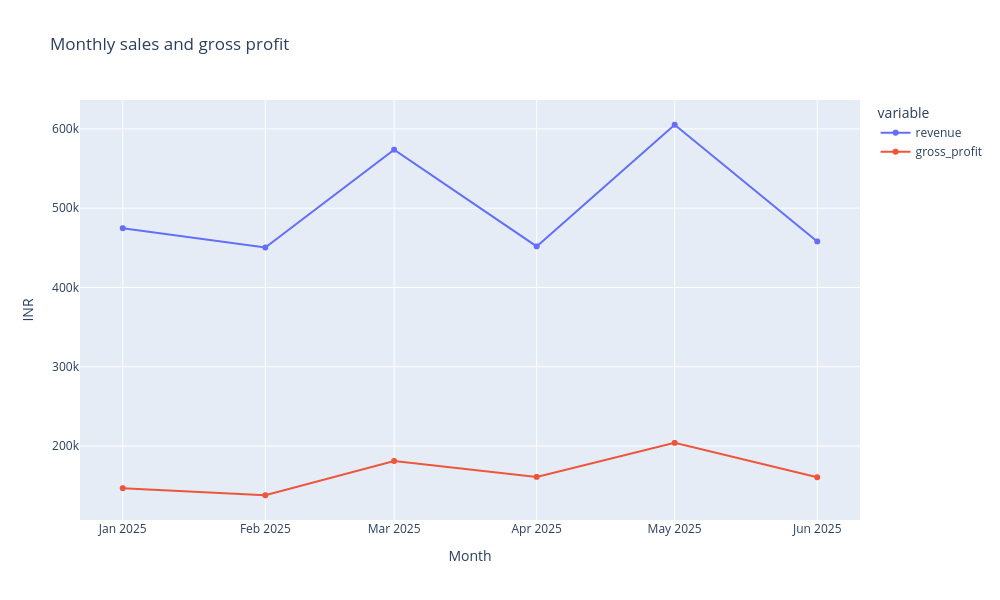

In [15]:
# Two y-column names produce two lines with a shared INR value axis.
fig = px.line(
    monthly, x="month", y=["revenue", "gross_profit"], markers=True,
    title="Monthly sales and gross profit",
    labels={"value": "INR", "month": "Month"},
)
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Each marker summarizes selected orders in one month, not an individual order. Both lines use INR, so their heights can be compared as monetary amounts. The profit line remains below sales because it subtracts product costs in this data. The interactive version supplies exact values on hover and lets readers hide a line through the legend. A higher total is not automatically higher daily demand, especially for partial months.

### Step 14 - Plot the category mix within each region

**Question:** Is a region's total explained by a particular product mix?

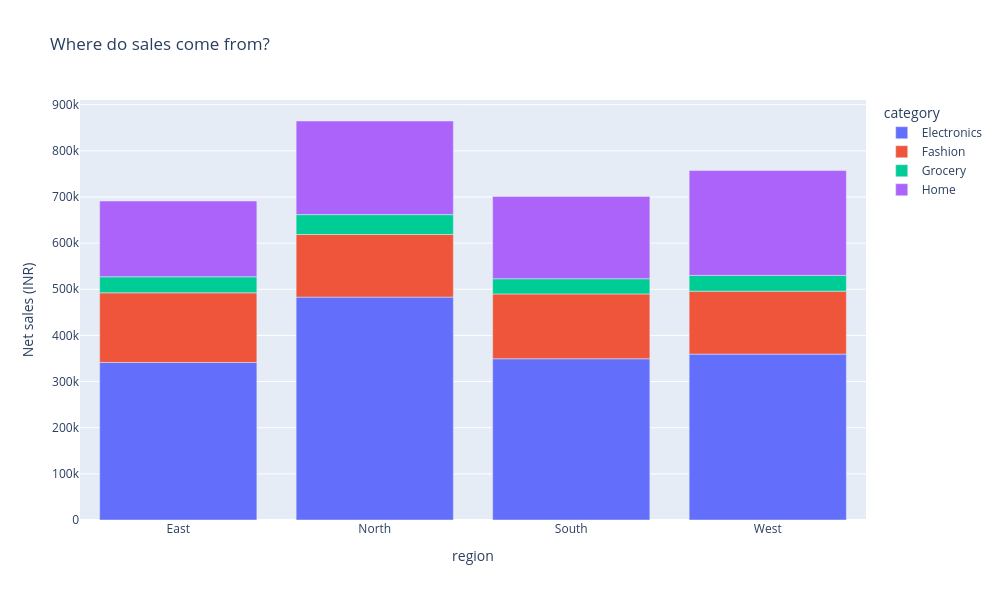

In [16]:
# Group by the pair so each region has a separate amount for each category.
by_region = filtered.groupby(["region", "category"], as_index=False)["revenue"].sum()
fig = px.bar(
    by_region, x="region", y="revenue", color="category",
    title="Where do sales come from?",
    labels={"revenue": "Net sales (INR)"},
)
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

The positive category contributions stack into each regional total. The bar's full height measures regional sales; each colored segment measures one category's contribution. It is a revenue-mix chart, not a margin chart. Large Electronics segments can reflect higher prices, more units or more orders; the data table is needed to investigate those explanations. Grouping by only region would lose the mix information.

### Step 15 - Plot the distribution of individual order values

**Question:** Does average order value represent an ordinary order?

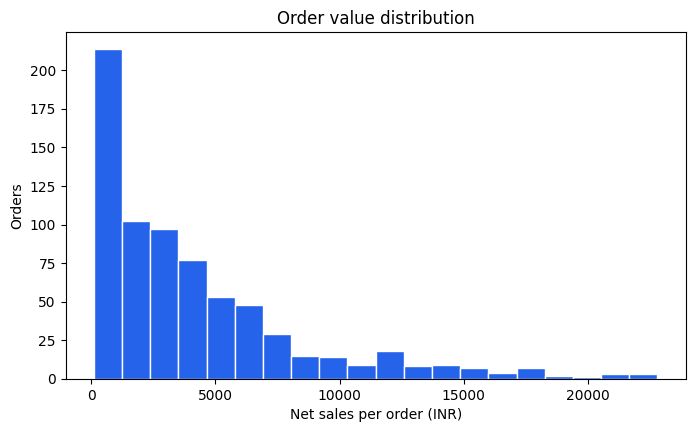

In [17]:
# Matplotlib separates the whole figure from the axes that receive commands.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(filtered["revenue"], bins=20, color="#2563eb", edgecolor="white")
ax.set(
    title="Order value distribution",
    xlabel="Net sales per order (INR)", ylabel="Orders",
)
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The horizontal axis is INR per order; the vertical axis counts orders in each of 20 ranges. The right tail shows larger orders that can pull the mean upward relative to the median. Twenty bins is a visualization choice: different bin counts change appearance, not the underlying transactions. A large order is not automatically invalid. The existing app displays this Matplotlib figure with `st.pyplot(fig)` and closes it afterward with `plt.close(fig)` to avoid accumulating figures across reruns.

### Step 16 - Compare order-level profit distributions by category

**Question:** Which categories have consistently profitable orders, and which vary widely?

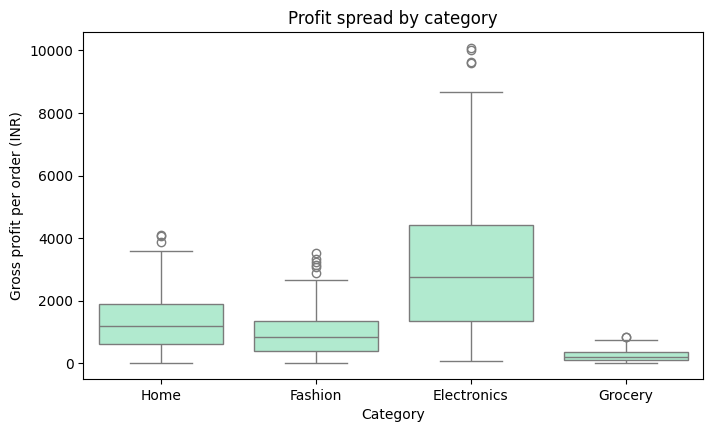

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# Seaborn uses the selected order rows, not the category-total table.
sns.boxplot(data=filtered, x="category", y="gross_profit", ax=ax, color="#a7f3d0")
ax.set(
    title="Profit spread by category",
    xlabel="Category", ylabel="Gross profit per order (INR)",
)
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The center line is the median; the box spans the middle 50% of order profits. Default whiskers reach observed values within 1.5 interquartile ranges of the box, with farther points shown individually. Those points are observations to inspect, not instructions to delete data. This chart describes profit per order, whereas the category table describes total profit and aggregate margin. Box widths are not sample-size encodings, so consult the order counts alongside it.

### Checkpoint - Read the formula before the correlation

Recall that gross profit is calculated partly from revenue. Predict a reason they might move together. Inspect the heatmap, then explain why this relationship alone cannot prove that a pricing or discount change caused a profit change.

### Step 17 - Calculate and plot correlations

**Question:** Which quantities move together in the selected orders?

              units  discount_pct  revenue  gross_profit
units          1.00         -0.02     0.47          0.41
discount_pct  -0.02          1.00    -0.19         -0.27
revenue        0.47         -0.19     1.00          0.90
gross_profit   0.41         -0.27     0.90          1.00


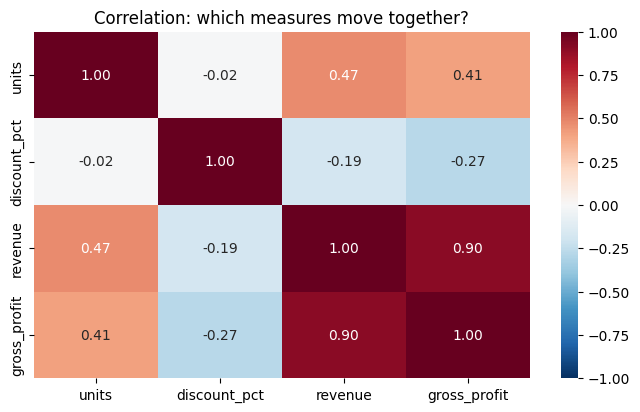

In [19]:
# corr() defaults to Pearson correlation between the selected numeric columns.
correlations = filtered[["units", "discount_pct", "revenue", "gross_profit"]].corr()
print(correlations.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(
    correlations, annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, ax=ax,  # Fix the same scale for every future selection.
)
ax.set_title("Correlation: which measures move together?")
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

Positive Pearson correlation means the quantities tend to rise together; negative means they tend to move in opposite directions. It measures linear association, not all possible relationships. The strong sales/profit correlation is partly mechanical because profit contains revenue in its formula. A discount/profit association is not proof of a causal promotion effect. Constant columns or too little data yield undefined cells, not meaningful zero correlations. No significance test or causal model is being fitted.

## Part 5 - Inspect, explain and export the evidence

### Step 18 - Inspect numeric summaries and extreme orders

**Question:** Which records explain the distribution's tail?

In [20]:
# describe gives count, mean, standard deviation, extremes and quartiles.
print(filtered.select_dtypes(include="number").describe().round(2).to_string())

# Sorting a separate view helps inspection without deleting any observations.
largest_orders = filtered.nlargest(3, "revenue")
print("\nThree largest orders:")
print(largest_orders[["order_id", "category", "units", "revenue", "gross_profit"]]
      .round(2).to_string(index=False))

        units  unit_price  discount_pct  unit_cost   revenue  gross_profit
count  720.00      720.00        720.00     720.00    720.00        720.00
mean     4.57      981.05          7.05     613.63   4186.34       1377.65
std      2.30      788.22          7.63     506.45   4278.34       1623.12
min      1.00      126.31          0.00      62.33    101.64          3.07
25%      2.75      246.70          0.00     174.71   1053.32        307.34
50%      5.00      789.60          5.00     477.57   2847.03        844.89
75%      7.00     1193.16         10.00     787.13   5696.44       1763.56
max      8.00     3068.24         20.00    2391.12  22798.96      10079.84

Three largest orders:
order_id    category  units  revenue  gross_profit
ORD-0323 Electronics      8 22798.96       6553.68
ORD-0319 Electronics      8 22494.88      10079.84
ORD-0126 Electronics      8 22274.16       9641.20


**Interpretation and reasoning**

The 50% row is the median; the 25% and 75% rows are quartiles. Standard deviation measures spread in each column's own unit, so do not compare a rupee spread with a percentage-point spread as if they were the same quantity. The three-order table is a teaching inspection beyond the source's numeric summary, using actual selected records. It identifies examples to investigate without automatically removing outliers or rewriting the source file.

### Step 19 - Make a focused North-versus-South comparison

**Question:** Is the larger sales total accompanied by more orders, a larger average order or a different margin?

In [21]:
# This new variable keeps the main filtered selection unchanged.
comparison_rows = filtered[filtered["region"].isin(["North", "South"])]
comparison = comparison_rows.groupby("region").agg(
    orders=("order_id", "size"),
    sales=("revenue", "sum"),
    profit=("gross_profit", "sum"),
    average_order=("revenue", "mean"),
)
comparison["margin_pct"] = 100 * comparison["profit"] / comparison["sales"]
print(comparison.round(2).to_string())

        orders      sales     profit  average_order  margin_pct
region                                                         
North      191  864633.53  293602.16        4526.88       33.96
South      166  701146.60  223176.87        4223.77       31.83


**Interpretation and reasoning**

This worked comparison uses the same date interval for both regions and keeps counts beside amounts. It illustrates why a regional sales leader is not automatically more productive. Store count, population and customer identities are absent, so those denominators cannot be recovered from a chart. The separate `comparison_rows` object ensures later report cells still describe the original default selection.

### Step 20 - Observe empty filters and undefined rates explicitly

**Question:** What should we infer when there are no selected rows or a denominator is zero?

In [22]:
# Membership in an empty list is False for every row.
empty_selection = frame[frame["region"].isin([])]
print("Orders after selecting no regions:", len(empty_selection))

# This is the original helper's programming fallback, not a defined margin.
print("Scalar ratio(100, 0) fallback:", ratio(100, 0))

# The source's grouped-margin formula instead marks a zero denominator missing.
example_profit = pd.Series([100.0], name="profit")
example_sales = pd.Series([0.0], name="sales")
undefined_margin = example_profit.div(example_sales.replace(0, float("nan")))
print("Grouped-margin result with zero sales:", undefined_margin.iloc[0])

Orders after selecting no regions: 0
Scalar ratio(100, 0) fallback: 0.0
Grouped-margin result with zero sales: nan


**Interpretation and reasoning**

The tiny zero-denominator Series is an explicit edge-case demonstration, separate from the bundled data. An empty selection should stop analysis; the Streamlit app shows a message and stops. A displayed fallback zero is not evidence of a genuine 0% margin. Group ratios use NaN, but the original `idxmax()`/leader-text path is unguarded if all selected category margins are NaN. The loader also does not enforce positive quantities, finite values, unique IDs or the documented 0-100 discount range.

### Step 21 - Record the scope so a finding has context

**Question:** What exactly does our report describe?

In [23]:
scope_parts = []
# Include low-cardinality text fields; omit hundreds of individual order IDs.
for column in frame.select_dtypes(include="object").columns:
    if frame[column].nunique() <= 12:
        labels = ", ".join(map(str, sorted(filtered[column].unique())))
        scope_parts.append(column.replace("_", " ") + ": " + labels)

# Observed dates and requested boundaries are related but not identical ideas.
scope_parts.append(
    f"Observed records: {filtered['order_date'].min():%Y-%m-%d} "
    f"to {filtered['order_date'].max():%Y-%m-%d}"
)
scope_parts.append(f"Requested dates: {dates[0]} to {dates[1]} (inclusive)")
scope = "; ".join(scope_parts)
print(scope)

region: East, North, South, West; category: Electronics, Fashion, Grocery, Home; channel: Online, Store; Observed records: 2025-01-01 to 2025-06-29; Requested dates: 2025-01-01 to 2025-06-29 (inclusive)


**Interpretation and reasoning**

This follows the source's low-cardinality-field and date-scope pattern. With another selection, a requested boundary may have no observed order, so observed minimum/maximum dates can differ from the control values. Scope is essential when comparing findings. It is a human-readable description, not a serialized copy of all data or a guarantee of reproducibility if the source CSV changes later.

### Step 22 - Turn calculations into evidence-based answer sentences

**Question:** How does the app write a conclusion that changes with the filters?

In [24]:
# f-strings insert measured values into fixed explanations; no AI call is needed.
insights = [
    ("How much business is represented?",
     f"{len(filtered):,} selected orders generated INR {revenue:,.2f} sales "
     f"and INR {profit:,.2f} gross profit."),
    ("Which region leads sales?",
     f"{top_region}: INR {sales_by_region[top_region]:,.2f}, "
     f"or {ratio(sales_by_region[top_region], revenue):.1%} of selected sales."),
    ("Which category leads sales?",
     f"{top_category}: INR {category_summary.loc[top_category, 'sales']:,.2f}."),
    ("Which category leads margin?",
     f"{margin_category}: {category_summary.loc[margin_category, 'margin']:.1%}."),
    ("What is a typical order worth?",
     f"Mean INR {average_order:,.2f}; median INR {median_order:,.2f}."),
    ("Which month contributed most sales?",
     f"{monthly_totals.idxmax()}: INR {monthly_totals.max():,.2f}."),
]
for question, answer in insights:
    print(question)
    print(answer)
    print()

How much business is represented?
720 selected orders generated INR 3,014,163.59 sales and INR 991,908.14 gross profit.

Which region leads sales?
North: INR 864,633.53, or 28.7% of selected sales.

Which category leads sales?
Electronics: INR 1,533,289.74.

Which category leads margin?
Electronics: 33.4%.

What is a typical order worth?
Mean INR 4,186.34; median INR 2,847.03.

Which month contributed most sales?
2025-05: INR 605,230.59.



**Interpretation and reasoning**

These concise teaching sentences use the same calculated facts as the source's fuller insights. `.loc[label, column]` retrieves a category result by its name; Series lookup retrieves a regional total. Because the sentences are rebuilt after filtering, they follow the selection instead of becoming stale manually typed claims. The source shows the first three insights in its short summary and all six in its full report. Tied maxima are named according to the first maximum in the grouped ordering, so inspect tables before claiming a unique winner.

### Step 23 - Build a readable source-field dictionary

**Question:** How can the report keep units and row meaning close to the numbers?

In [25]:
# A dictionary associates exact field names with their meaning and units.
field_guide = {
    "order_id": "One synthetic order identifier",
    "order_date": "Order date; inclusive filter boundaries",
    "region": "Sales region",
    "category": "Product category represented by the order",
    "channel": "Store or Online sales channel",
    "units": "Units sold in the order",
    "unit_price": "INR per unit before discount",
    "discount_pct": "Discount percentage points, intended 0-100",
    "unit_cost": "Product cost in INR per unit",
}
dictionary_table = pd.DataFrame(field_guide.items(), columns=["Field", "Meaning"])
print(dictionary_table.to_string(index=False))

       Field                                    Meaning
    order_id             One synthetic order identifier
  order_date    Order date; inclusive filter boundaries
      region                               Sales region
    category  Product category represented by the order
     channel              Store or Online sales channel
       units                    Units sold in the order
  unit_price               INR per unit before discount
discount_pct Discount percentage points, intended 0-100
   unit_cost               Product cost in INR per unit


**Interpretation and reasoning**

`.items()` supplies key/value pairs; the DataFrame constructor turns them into a two-column table. The original app keeps its field definitions in `FIELD_GUIDE` and reuses them on screen and in report text. A field dictionary documents a convention; it does not enforce it. A price accidentally recorded in paise would still parse as numeric but would have the wrong business unit.

### Checkpoint - Make a finding reproducible

Choose one answer sentence from the earlier cell. Can another reader identify its selected rows, units and calculation? Inspect the scope text before generating the report. Explain how the report should change if the date window contains only part of a month.

### Step 24 - Assemble a compact Markdown report from the same results

**Question:** How do Python calculations become a Markdown document?

In [26]:
kpi_values = [
    ("Net sales (INR)", f"{revenue:,.2f}"),
    ("Gross profit (INR)", f"{profit:,.2f}"),
    ("Gross margin", f"{ratio(profit, revenue):.2%}"),
    ("Average order (INR)", f"{average_order:,.2f}"),
]

# Each element is a report section. join inserts the Markdown line breaks.
report_parts = [
    "# Retail sales - teaching report",
    "## Business question\nWhere should the manager investigate sales, costs and margins?",
    "## Scope\n" + scope,
    "## KPI results\n| Measure | Result |\n| --- | --- |\n"
    + "\n".join(f"| {name} | {value} |" for name, value in kpi_values),
    "## Questions answered\n"
    + "\n\n".join(f"### {question}\n{answer}" for question, answer in insights),
    "## Source fields\n| Field | Meaning |\n| --- | --- |\n"
    + "\n".join(f"| {name} | {meaning} |" for name, meaning in field_guide.items()),
    "## Limits\nFictional orders. Gross profit excludes operating expenses and tax. "
    "Group totals do not establish causation or forecast future demand.",
]
full_report = "\n\n".join(report_parts)

# Print an actual excerpt, rather than claiming to display the whole report.
print("\n".join(full_report.splitlines()[:23]))
print("\n[Preview ends; full_report contains the remaining sections.]")

# Retail sales - teaching report

## Business question
Where should the manager investigate sales, costs and margins?

## Scope
region: East, North, South, West; category: Electronics, Fashion, Grocery, Home; channel: Online, Store; Observed records: 2025-01-01 to 2025-06-29; Requested dates: 2025-01-01 to 2025-06-29 (inclusive)

## KPI results
| Measure | Result |
| --- | --- |
| Net sales (INR) | 3,014,163.59 |
| Gross profit (INR) | 991,908.14 |
| Gross margin | 32.91% |
| Average order (INR) | 4,186.34 |

## Questions answered
### How much business is represented?
720 selected orders generated INR 3,014,163.59 sales and INR 991,908.14 gross profit.

### Which region leads sales?
North: INR 864,633.53, or 28.7% of selected sales.


[Preview ends; full_report contains the remaining sections.]


**Interpretation and reasoning**

The output is an executed excerpt of a deliberately shorter teaching report. `
` means a newline, pipes form Markdown table columns, and generator expressions produce repeated rows or question sections. The existing app uses the same list/f-string/join technique for 12 sections including all visual guides, quality counts, recommendations and limitations. Its field dictionary is appended to `report_parts[5]`, which is the KPI-results section because the title occupies index zero. That detail affects placement, not the numerical analysis. Neither report is generated by an AI service.

### Step 25 - Preview the exact shape of a filtered CSV download

**Question:** What would the user receive when downloading the selected data?

In [27]:
# index=False excludes the internal pandas index from the exported file.
csv_text = filtered.to_csv(index=False)
print("\n".join(csv_text.splitlines()[:4]))
print(f"\nExport contains {len(filtered)} order rows and {len(filtered.columns)} columns.")

order_id,order_date,region,category,channel,units,unit_price,discount_pct,unit_cost,revenue,gross_profit
ORD-0001,2025-01-01,West,Home,Store,7,1043.19,0.0,658.69,7302.33,2691.5
ORD-0002,2025-01-02,East,Home,Online,2,766.05,0.0,435.11,1532.1,661.8799999999999
ORD-0003,2025-01-03,South,Home,Store,7,1098.99,0.0,807.3,7692.93,2041.8300000000008

Export contains 720 order rows and 11 columns.


**Interpretation and reasoning**

The output contains the source fields plus `revenue` and `gross_profit`, because they were added to `filtered`. This cell creates text in memory; it does not overwrite `retail_sales.csv`. In Streamlit, `st.download_button(..., csv_text, ..., 'text/csv')` offers that text to the browser. Sorting a displayed table does not change analytical filters or this underlying selection.

## Part 6 - Turn the analysis into a Streamlit app

The analysis above already works without a browser UI. Streamlit adds controls and display commands around the same sequence. The roles remain clear: pandas calculates, Plotly/Matplotlib/Seaborn construct figures, and Streamlit receives widget values and renders outputs.

The complete Streamlit reference script below is **one separate application**. It has its own imports and loading code, so it does not depend on notebook variables. Copy only its Python code into `practice_app.py` beside the CSV, then run:

```bash
python -m streamlit run practice_app.py
```

In a CookieSensei workspace whose built-in dashboard already uses 8501, run `python -m streamlit run practice_app.py --server.port 8502` and open that forwarded port. To run the existing fuller project instead, use the same command with `app.py`.

**What happens on interaction?** A normal widget change reruns the script from top to bottom using the current values. `st.sidebar.multiselect()` returns a list used in `.isin()`. The date widget returns an interval, which is checked before indexing its two ends. `st.stop()` prevents invalid or empty data from reaching the calculations. Loading is uncached, so a saved CSV edit is read on the next rerun; no automatic CSV watcher is promised.

`st.columns()` and `with tab:` arrange output. In the pinned Streamlit 1.50 version, all tab contents execute on a full rerun, including hidden tabs. Expander visibility likewise does not make computation lazy. Plotly zoom, table sorting and tab selection do not become additional pandas filters in this app.

This compact reconstruction includes the same default measures and five chart types, but shorter business text and a shorter report. It does not replace or modify the original source. Its small all-undefined-margin guard below is an explicit teaching improvement; the original app does not guard that leader edge case.

### Step 26 - Build the separate interactive retail teaching app

**Question:** How can a reader change the analysis without editing pandas code?

## Connect notebook state to the existing retail app

Use this mapping while reading [app.py](app.py). The complete script supplies the fuller business context and report described in [EXPLANATION.md](EXPLANATION.md); the final teaching app is a compact reconstruction.

| Notebook evidence | Existing app component | Why the connection matters |
| --- | --- | --- |
| `selected_regions`, `selected_categories`, `dates` | Sidebar `selected_region`, `selected_category` and date widgets | The notebook assigns choices; browser controls return the choices in the app |
| `filtered`, its derived columns, `revenue` and `profit` | Net sales, gross profit, gross margin and average-order cards | Every card describes the same selected orders |
| `monthly` and `by_region` | Two charts in **Sales dashboard** | Grouped rows become monthly totals or region/category totals |
| Order revenue, order profit and correlations | Three charts in **Explore the data** | Distributions and relationships complement the totals |
| `filtered`, field meanings and summaries | **Data and quality**, including the CSV download | A learner can inspect the evidence underlying a card |
| `insights`, scope and `full_report` | **Full report** and its Markdown download | The conclusions travel with their analytical context |

A sidebar change reruns the script from the top with the current widget values. The app reads the CSV again because this loader is not cached; editing a CSV does not itself guarantee a rerun. It stops before analysis if dates are incomplete or the selection is empty. Source-quality displays describe `frame`, while business results describe `filtered`.

Unlike separately executed notebook cells, a normal app rerun rebuilds the downstream pipeline together. Streamlit 1.50 computes all these tab bodies, including hidden tabs. The script uses explicit display calls and closes Matplotlib figures after rendering. Downloads serialize the current selection or report in memory; they do not replace the source CSV.

Runnable AppTest cells inspect the sibling app and demonstrate a real filter rerun without starting a server. The complete teaching script remains a Markdown reference; save it separately to run Streamlit in a browser.

### Complete Streamlit teaching script - reference

The following complete script is shown in a **Markdown reference cell**. It is intended for the separate `.py` file described above, because Streamlit renders controls and pages through its own server execution. The analysis cells in this notebook have already calculated and explained the measures used here.

```python
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import streamlit as st

st.set_page_config(page_title="Retail Sales Explorer", layout="wide")
st.title("Retail Sales Explorer")
st.caption("Teaching reconstruction | Fictional orders | Currency: INR")

# In a script, __file__ lets us find the CSV beside this application.
data_file = Path(__file__).resolve().with_name("retail_sales.csv")
required = ["order_id", "order_date", "region", "category", "channel",
            "units", "unit_price", "discount_pct", "unit_cost"]
try:
    frame = pd.read_csv(data_file)
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError("Provide a nonempty CSV with all required columns.")
    frame["order_date"] = pd.to_datetime(frame["order_date"], errors="raise")
    for column in ["units", "unit_price", "discount_pct", "unit_cost"]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if frame[required].isna().any().any():
        raise ValueError("Fill missing required values first.")
except (OSError, ValueError, KeyError) as error:
    st.error(str(error))
    st.stop()  # Do not calculate with invalid or unavailable data.

# Widget return values feed the same membership/date filters used above.
regions = st.sidebar.multiselect("Regions", sorted(frame["region"].unique()),
                                default=sorted(frame["region"].unique()))
categories = st.sidebar.multiselect("Categories", sorted(frame["category"].unique()),
                                   default=sorted(frame["category"].unique()))
dates = st.sidebar.date_input(
    "Date range", (frame["order_date"].min().date(), frame["order_date"].max().date()),
    min_value=frame["order_date"].min().date(), max_value=frame["order_date"].max().date(),
)
if len(dates) != 2:
    st.info("Choose both a start and an end date.")
    st.stop()
filtered = frame[frame["region"].isin(regions) & frame["category"].isin(categories)].copy()
filtered = filtered[filtered["order_date"].dt.date.between(dates[0], dates[1])]
if filtered.empty:
    st.info("No rows match. Select a group or widen the date range.")
    st.stop()

# Compute once for the current selection, then reuse the results everywhere.
filtered["revenue"] = filtered["units"] * filtered["unit_price"] * (1 - filtered["discount_pct"] / 100)
filtered["gross_profit"] = filtered["revenue"] - filtered["units"] * filtered["unit_cost"]
sales = filtered["revenue"].sum()
profit = filtered["gross_profit"].sum()
margin = profit / sales if sales else 0.0  # Source-style fallback; undefined if sales=0.
cards = st.columns(4)
cards[0].metric("Net sales (INR)", f"{sales:,.0f}")
cards[1].metric("Gross profit (INR)", f"{profit:,.0f}")
cards[2].metric("Gross margin", f"{margin:.1%}")
cards[3].metric("Average order (INR)", f"{filtered['revenue'].mean():,.0f}")

category_summary = filtered.groupby("category").agg(
    sales=("revenue", "sum"), profit=("gross_profit", "sum"), orders=("revenue", "size"),
)
category_summary["margin"] = category_summary["profit"].div(category_summary["sales"].replace(0, float("nan")))
valid_margins = category_summary["margin"].dropna()
# Teaching improvement: the existing source does not guard this all-NaN case.
margin_leader = valid_margins.idxmax() if not valid_margins.empty else "Undefined"

dashboard, explore, data_tab, report_tab = st.tabs(["Dashboard", "Explore", "Data", "Report"])
with dashboard:
    monthly = filtered.assign(month=filtered["order_date"].dt.to_period("M").astype(str))
    monthly = monthly.groupby("month", as_index=False)[["revenue", "gross_profit"]].sum()
    st.plotly_chart(px.line(monthly, x="month", y=["revenue", "gross_profit"], markers=True,
                           title="Monthly sales and gross profit"), use_container_width=True)
    regional = filtered.groupby(["region", "category"], as_index=False)["revenue"].sum()
    st.plotly_chart(px.bar(regional, x="region", y="revenue", color="category",
                          title="Regional category mix"), use_container_width=True)
    st.dataframe(category_summary.round(2), width="stretch")
with explore:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(filtered["revenue"], bins=20, color="#2563eb", edgecolor="white")
    ax.set(title="Order value distribution", xlabel="Net sales per order (INR)", ylabel="Orders")
    st.pyplot(fig)
    plt.close(fig)  # Release the Matplotlib figure after Streamlit renders it.

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=filtered, x="category", y="gross_profit", ax=ax, color="#a7f3d0")
    ax.set(title="Profit by category", ylabel="Gross profit per order (INR)")
    st.pyplot(fig)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.heatmap(filtered[["units", "discount_pct", "revenue", "gross_profit"]].corr(),
                annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", ax=ax)
    ax.set_title("Correlation is association, not causation")
    st.pyplot(fig)
    plt.close(fig)
with data_tab:
    st.dataframe(filtered, hide_index=True, width="stretch")
    st.download_button("Download filtered CSV", filtered.to_csv(index=False),
                       "filtered_retail_sales.csv", "text/csv")
with report_tab:
    # Build text from this run's selected data rather than typing fixed results.
    report_parts = [
        "# Retail sales - teaching report",
        f"Selected {len(filtered)} orders, {dates[0]} to {dates[1]}.",
        f"Regions: {', '.join(regions)}. Categories: {', '.join(categories)}.",
        f"Sales: INR {sales:,.2f}. Gross profit: INR {profit:,.2f}. Margin: {margin:.2%}.",
        f"Highest defined category margin: {margin_leader}.",
        "Fictional data. Gross profit excludes operating expenses and tax. No causal effect is estimated.",
    ]
    report = "\n\n".join(report_parts)
    st.markdown(report)
    st.download_button("Download teaching report", report, "retail_teaching_report.md", "text/markdown")
```

## Inspect the actual Streamlit application from this notebook

The companion script above is a compact teaching reconstruction. The next executable cells inspect the **existing sibling `app.py`**, which also contains the complete business context, chart explanations and full report.

`AppTest` is Streamlit's testing interface. It runs the application and lets Python inspect the UI elements it produced. It does not start a browser server. We use it here to connect the notebook's calculations with the application's real labels and values. The displayed tables summarize application elements; they are not browser screenshots.

### Load and run the sibling app

`AppTest.from_file(...)` reads a saved Streamlit script; `.run()` executes it with default widget values. The checks stop this cell if the app raises an exception or displays a loading error. Keeping `app.py` beside its CSV lets its `Path(__file__)` lookup work independently of notebook variables.

In [28]:
from streamlit.testing.v1 import AppTest  # Inspect Streamlit output without launching a server.
import logging

# AppTest intentionally runs without a browser session; quiet its context-only warning.
# Application errors are still checked explicitly below.
logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context').setLevel(logging.ERROR)

app_file = PROJECT_DIR / 'app.py'
app_preview = AppTest.from_file(str(app_file), default_timeout=45).run()
if len(app_preview.exception):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.exception))
if len(app_preview.error):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.error))

print('Script:', app_file.name)
print('Title:', app_preview.title[0].value)
print('Default application run completed.')

Script: app.py
Title: Retail Sales Explorer
Default application run completed.


### Read the controls, KPI cards and output containers

The values below come from the application instance that just ran. A metric element has a `label` and a formatted `value`; a multiselect has the current list of choices. The table dimensions describe what the app actually rendered. Chart counts distinguish interactive Plotly figures from Matplotlib/Seaborn images.

In [29]:
# Turn rendered KPI cards into an ordinary table we can inspect in the notebook.
baseline_cards = {metric.label: metric.value for metric in app_preview.metric}
display(pd.DataFrame(baseline_cards.items(), columns=['Dashboard measure', 'Displayed value']))

for widget in app_preview.multiselect:
    print(widget.label + ': ' + ', '.join(map(str, widget.value)))
for widget in app_preview.date_input:
    print(widget.label + ': ' + ' to '.join(map(str, widget.value)))
for widget in app_preview.slider:
    print(widget.label + ': ' + str(widget.value))
for index, table in enumerate(app_preview.dataframe, start=1):
    print(f'Table {index}: {len(table.value)} rows x {len(table.value.columns)} columns')
print('Interactive Plotly charts:', len(app_preview.get('plotly_chart')))
print('Rendered statistical charts:', len(app_preview.get('imgs')))
for button in app_preview.get('download_button'):
    print('Download:', button.proto.label)

,Dashboard measure,Displayed value
0,Net sales (INR),"3,014,164"
1,Gross profit (INR),"991,908"
2,Gross margin,32.9%
3,Average order (INR),"4,186"


Regions: East, North, South, West
Categories: Electronics, Fashion, Grocery, Home
Date range: 2025-01-01 to 2025-06-29
Table 1: 4 rows x 3 columns
Table 2: 4 rows x 4 columns
Table 3: 9 rows x 2 columns
Table 4: 720 rows x 11 columns
Table 5: 8 rows x 6 columns
Table 6: 9 rows x 3 columns
Interactive Plotly charts: 2
Rendered statistical charts: 3
Download: Download filtered CSV
Download: Download full report (Markdown)


### Change one filter and observe a real app rerun

This cell selects one value in the first multiselect and compares the resulting KPI cards with the baseline. `.set_value(...)` changes the control; `.run()` executes the app again. We then restore the complete selection so the preview ends in its default state.

The notebook's own `frame` and `filtered` variables belong to the analysis session. `AppTest` executes the script in its own application context, so changing this preview does not silently alter the earlier notebook analysis. In the live browser app, the corresponding widget interaction triggers the rerun for you.

In [30]:
# Keep all original choices so the application can be restored after this experiment.
first_control = app_preview.multiselect[0]
original_choices = list(first_control.value)
one_choice = original_choices[0]
control_label = first_control.label

# This is the programmatic equivalent of narrowing a sidebar multiselect.
first_control.set_value([one_choice]).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The narrowed app selection did not complete successfully.')
selected_cards = {metric.label: metric.value for metric in app_preview.metric}
comparison = pd.DataFrame({
    'Dashboard measure': list(baseline_cards),
    'All choices': list(baseline_cards.values()),
    f'{control_label}: {one_choice}': [selected_cards[label] for label in baseline_cards],
})
display(comparison)

# Restore the baseline; the notebook data and the source CSV have not been edited.
app_preview.multiselect[0].set_value(original_choices).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The application could not restore its original selection.')
print('Restored', control_label + ':', ', '.join(map(str, original_choices)))

,Dashboard measure,All choices,Regions: East
0,Net sales (INR),"3,014,164","691,161"
1,Gross profit (INR),"991,908","227,924"
2,Gross margin,32.9%,33.0%
3,Average order (INR),"4,186","4,114"


Restored Regions: East, North, South, West


### Open the browser interface

In a **terminal in this project folder**, run:

```bash
python -m streamlit run app.py --server.port 8502
```

Open the displayed local URL, or forward port 8502 in Cloud Labs. The built-in workshop dashboard uses port 8501. Streamlit keeps running while the page is available; stop it with **Ctrl+C** in that terminal. This command is a terminal instruction, so **Run All** in this notebook does not start the server.

Follow one choice through the app: widget value → pandas row selection → derived columns → grouped results → cards/charts/report. This is the connection between the analysis and its browser interface.

## Limits, troubleshooting and next questions

The source checks required columns, parseable dates/numbers, nonmissing essential cells, an empty CSV and empty/incomplete selections. It does not enforce unique order IDs, whole positive quantities, finite values, nonnegative prices/costs or a 0-100 discount range. Its field dictionary describes those units and intended ranges; it does not validate them. Exact duplicates are reported rather than removed. Only initial loading is inside the source's error handler, so invalid business values can still fail later calculations or charts.

The scalar `ratio()` uses zero as a programming fallback, while group margins use NaN for a zero denominator. The original category-leader calculation can fail when every margin is undefined. Correlations can be missing for small or constant selections. The guide's explicit edge-case cell and the final teaching app's labeled guard do not silently change `app.py`.

Sales are not verified cash collection; gross profit is not net profit. Customer IDs, returns, store sizes, operating expenses and acquisition costs are absent. Region totals cannot measure per-store productivity, and discount associations cannot establish a causal response. A strong conclusion names the selection, measured result, supporting sample size and the extra information needed for a decision.

| If you see this | What to check |
| --- | --- |
| A missing-library error | Use the intended Python environment and install packages with that interpreter's `python -m pip`. |
| A CSV-not-found error in a notebook | Start the notebook in `01_retail_sales`; the teaching cells intentionally use that working directory. |
| A CSV-not-found error in the app | Keep the named CSV beside the script; its `__file__` path is script-relative. |
| An error after editing dates/numbers | Inspect the exact changed values. The app deliberately raises instead of silently discarding them. |
| No rows match | Restore a region/category or widen dates. Empty selections are not interpreted as all values. |
| Saved CSV changes do not appear | Save and trigger a rerun. The read is uncached, but a new execution is still needed. |
| Different decimal places on a card and report | Compare formatting; cards round some amounts to whole INR while reports retain more precision. |
| A heatmap cell is blank | Check sample size and whether a variable is constant. A blank correlation is not automatically zero. |

For practice, change the analysis-cell selection to North and South, rerun subsequent cells, and compare the results. Add a channel control **before** deriving measures and keep the final empty-data guard after all filters. Explain one difference between a total, a mean, a median and a weighted margin using the real resulting output. Treat price changes or discount changes as explicit arithmetic scenarios unless you have data that models demand response.

## Sources

- [Existing project source](app.py), [bundled dataset](retail_sales.csv), [workshop README](../README.md) and [repository README](../../README.md) ground the implementation and the executed outputs.
- [pandas 2.2 introduction](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/10min.html) and [GroupBy guide](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/groupby.html) explain the tabular operations.
- [pandas correlation reference](https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.DataFrame.corr.html) documents Pearson correlation and missing results.
- [Streamlit main concepts](https://docs.streamlit.io/get-started/fundamentals/main-concepts), [run instructions](https://docs.streamlit.io/develop/concepts/architecture/run-your-app) and [Streamlit 1.50 tabs](https://docs.streamlit.io/1.50.0/develop/api-reference/layout/st.tabs) explain execution and layout.
- [Plotly Express](https://plotly.com/python/plotly-express/), [Matplotlib histogram](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html), [Matplotlib close](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.close.html), [Seaborn boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html) and [Seaborn heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) explain the chart functions used here.

## Practice explaining a changed result

1. **Compare North and South over the same period.** Change only the region selection and rerun downstream analysis. Hint: retain order counts alongside revenue and average order value. Is a difference mainly about the number of orders, their values, or both? What remains unknown about regional productivity?
2. **Inspect one category in depth.** Select a category and compare aggregate margin with the order-profit boxplot. Hint: margin is profit divided by sales; the boxplot uses profit amounts per order. Can a high-margin category still have modest profit per order? Explain the different units.
3. **Create a partial-month window.** Choose a date range that starts midway through a month. Hint: inspect actual retained dates and counts before comparing monthly bars or points. What additional exposure information would make a growth claim more defensible?

Restore the default selection when finished and rerun the analysis so that saved outputs tell one consistent story.

### Explanation checklist

For any finding, name the row grain, selection, numerator, denominator, units and supporting output. Explain why that operation answers the question. Check whether the conclusion concerns size, efficiency or variation. State one additional piece of evidence needed before making a business decision.

## Finish with an explanation you can defend

Before presenting the project, explain one complete chain in your own words: **the question, the source rows, the operation, the result, and the decision it informs**. State the units and denominator. Show a supporting table or chart and one limitation. Then restart the kernel and run the notebook from the top to confirm that the result does not depend on forgotten interactive state.

Notebook and application references: [Jupyter notebook structure](https://nbformat.readthedocs.io/en/latest/format_description.html), [Plotly notebook renderers](https://plotly.com/python/renderers/), and [Streamlit 1.50 AppTest](https://docs.streamlit.io/1.50.0/develop/api-reference/app-testing/st.testing.v1.apptest).